In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

In [ ]:
df = pd.read_csv('/content/credit_risk_dataset.csv')

In [ ]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
df.shape

(32581, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [ ]:
df.head()
df['loan_status'].unique()

df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

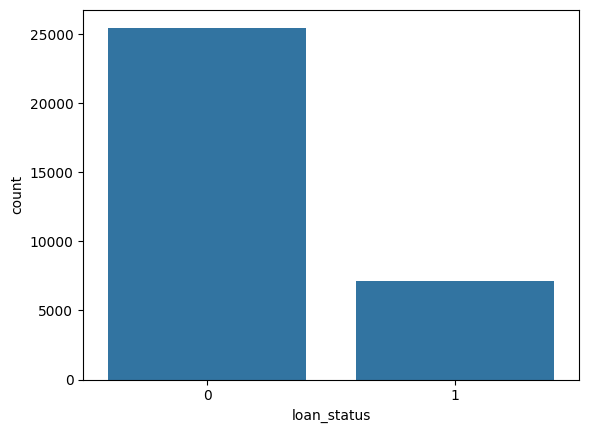

In [ ]:
sns.countplot(x='loan_status',data=df)

In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns
numerical_cols = numerical_cols.drop('loan_status')

In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
numerical_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')

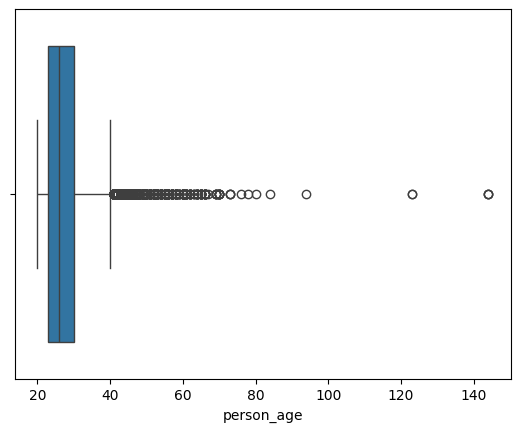

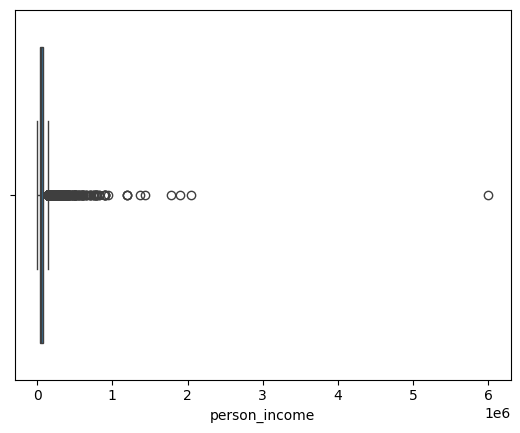

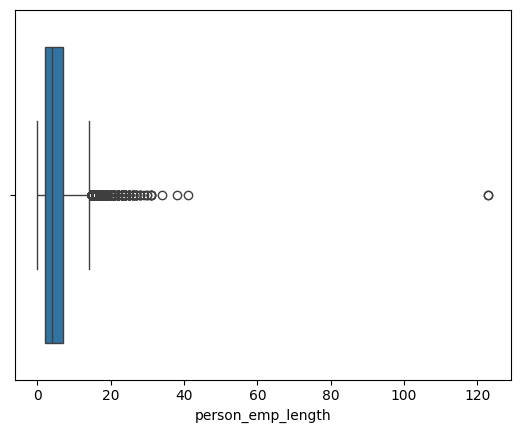

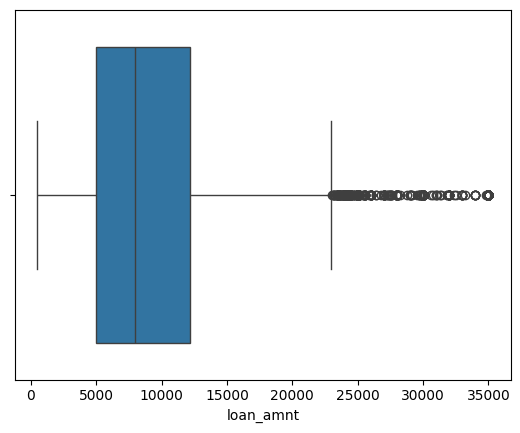

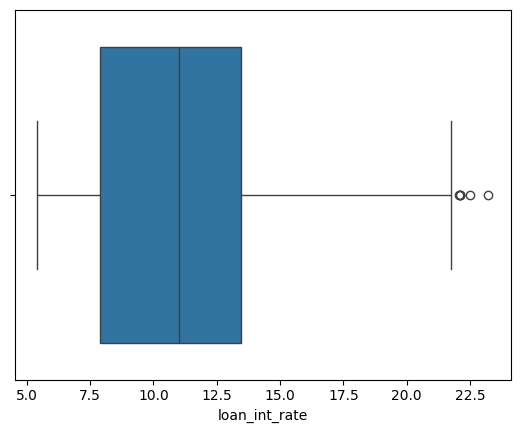

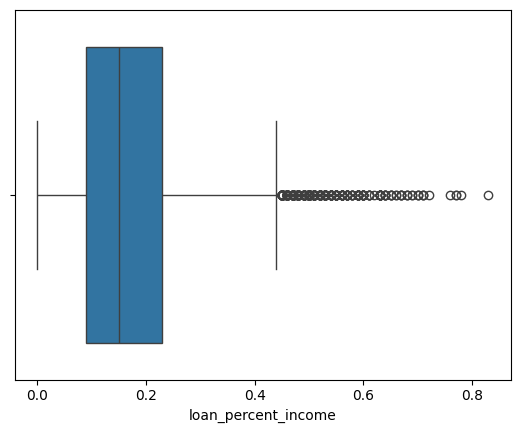

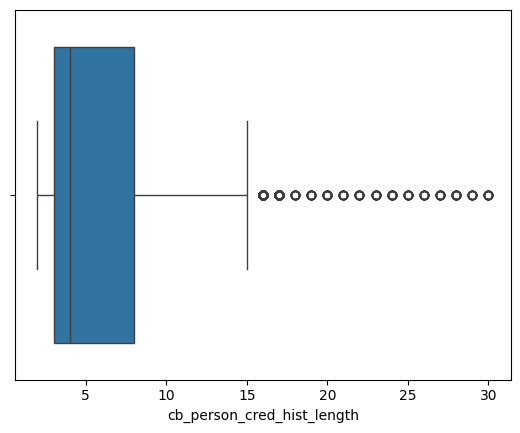

In [ ]:
for i in numerical_cols:
  sns.boxplot(x = df[i])
  plt.show()



In [ ]:
(df['person_age']>=100).sum()

np.int64(5)

In [ ]:
(df['person_emp_length']>60).sum()

np.int64(2)

<Axes: >

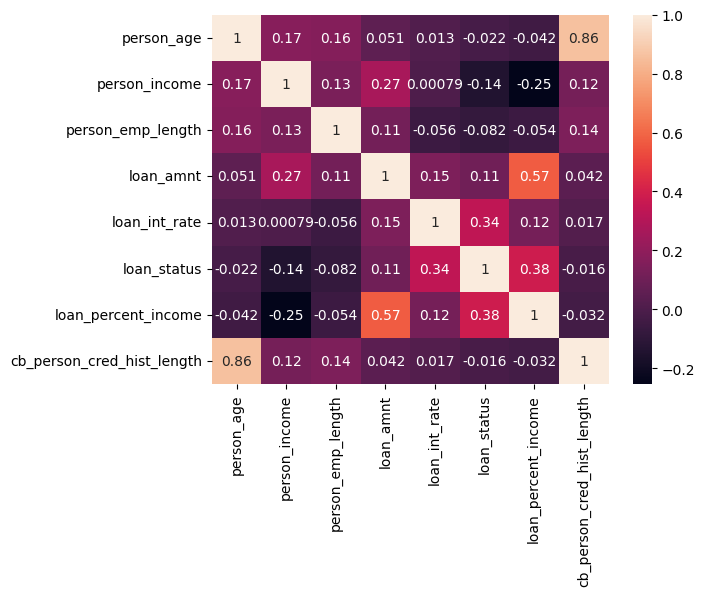

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [ ]:
df_copy = df.copy()

In [ ]:
df_copy.drop_duplicates(inplace= True)
df_copy.shape[0]

32416

In [ ]:
df_copy =df_copy[df_copy['person_age']>=18]
df_copy= df_copy[df_copy['person_age']<=100]

In [ ]:
df_copy = df_copy[df_copy['person_emp_length']<=df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length']<= 60]

In [ ]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
df_copy = df_copy[df_copy['loan_amnt']>0]

In [ ]:
df_copy = df_copy

In [ ]:
X = df_copy.drop('loan_status',axis=1)
y = df_copy['loan_status']


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [ ]:
from pandas.core.arrays import categorical
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

In [ ]:
y_train.value_counts()

,count
loan_status,
0,19772
1,5445


In [ ]:
neg,pos = np.bincount(y_train)

In [ ]:
scale_weights = neg/pos

In [ ]:
scale_weights

np.float64(3.6312213039485766)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

preprocessor_lr = ColumnTransformer(
    transformers=[
          ('num', Pipeline([
              ('imputer', SimpleImputer(strategy='median')),
              ('scaler', StandardScaler())
           ]), numeric_cols),
          ('cat', Pipeline([
              ('imputer', SimpleImputer(strategy='constant', fill_value="Missing")),
              ('onehot', OneHotEncoder(handle_unknown='ignore'))
          ]), categorical_cols)
    ]
)

In [ ]:
preprocessor_xgb = ColumnTransformer(
    transformers=[
          ('num', Pipeline([
              ('imputer', SimpleImputer(strategy='median')),
            ]), numeric_cols),
          ('cat', Pipeline([
              ('imputer', SimpleImputer(strategy='constant', fill_value="Missing")),
              ('onehot', OneHotEncoder(handle_unknown='ignore'))
          ]), categorical_cols)
    ]
)

In [ ]:
from sklearn.model_selection import StratifiedKFold,cross_validate

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

scoring = {'roc_auc':'roc_auc','accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'}


In [ ]:
cv

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [ ]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [ ]:
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xgb),
    ('classifier', XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=scale_weights,
        random_state=42))
])

In [ ]:
def eval_model_fixed(model_name, model, X_test, y_test,threshold = None):
  y_pred = model.predict(X_test)
  y_pred_proba = model.predict_proba(X_test)[:,1]

  if threshold:
    y_pred = (y_pred_proba >= threshold).astype(int)

  else:
    y_pred = model.predict(X_test)
  print(f"Model Name: {model_name}")
  print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
  print(f"Precision: {precision_score(y_test, y_pred)}")
  print(f"Recall: {recall_score(y_test, y_pred)}")
  print(f"F1 Score: {f1_score(y_test, y_pred)}")
  print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba)}")
  print(classification_report(y_test, y_pred))
  print(confusion_matrix(y_test, y_pred))

  sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
  plt.title(f"{model_name} Confusion Matrix")
  plt.xlabel("Predicted")
  plt.ylabel("Actual")
  plt.show()

  precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

In [ ]:
cv_results = {}

for cv_name, pipe in [('Logistic Regression', lr_cv_pipeline),
                      ('XGBoost', xgb_cv_pipeline)]:
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[cv_name] = {
        'ROC-AUC': scores['test_roc_auc'].mean(),
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-Score': scores['test_f1'].mean()
    }

df_results = pd.DataFrame(cv_results).T
display(df_results)

,ROC-AUC,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.870511,0.811595,0.544823,0.778145,0.640801
XGBoost,0.947095,0.917952,0.819080,0.796327,0.807336


In [ ]:
print(cv_name)

XGBoost


In [ ]:
baseline_lr = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [ ]:
baseline_lr

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
baseline_lr.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

Model Name: Baseline Logistic Regression
Accuracy: 0.8193497224425059
Precision: 0.5580426861009891
Recall: 0.7870778267254038
F1 Score: 0.6530612244897959
ROC-AUC: 0.8751287437432844
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305

[[4094  849]
 [ 290 1072]]


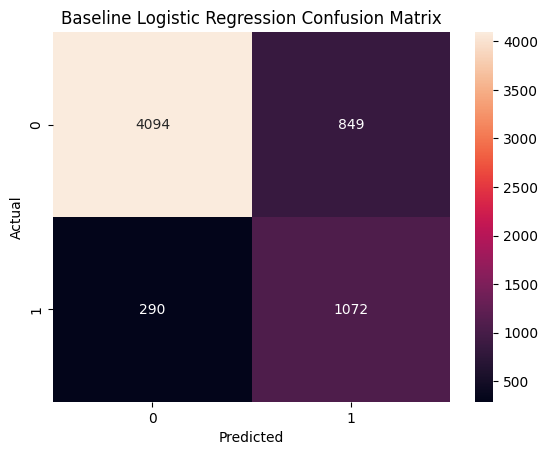

NameError: name 'precision_recall_curve' is not defined

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Note: If 'precision_recall_curve_plot' or 'roc_curve_plot' are custom helper functions, make sure they are defined or imported.
eval_model_fixed("Baseline Logistic Regression", baseline_lr, X_test, y_test)

In [ ]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xgb),
    ('classifier',XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=scale_weights,
        random_state=42
    ))
])

xg_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

Model Name: XGBoost
Accuracy: 0.9189532117367168
Precision: 0.8163568773234201
Recall: 0.8061674008810573
F1 Score: 0.8112301440709272
ROC-AUC: 0.9503436087699331
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.82      0.81      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305

[[4696  247]
 [ 264 1098]]


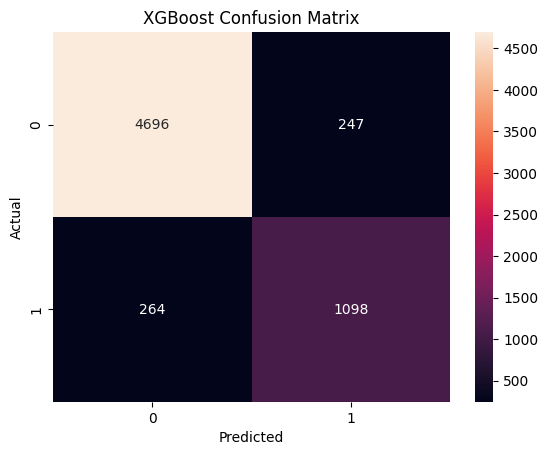

NameError: name 'precision_recall_curve' is not defined

In [ ]:

eval_model_fixed("XGBoost", xg_model, X_test, y_test)

In [ ]:
from scipy.stats import randint as sp_randint
from scipy.stats import uniform as sp_uniform

In [ ]:
import scipy.stats as stats

param_grid = {
    'classifier__n_estimators': stats.randint(150, 600),
    'classifier__max_depth': stats.randint(3, 9),
    'classifier__learning_rate': stats.uniform(0.01, 0.5),
    'classifier__scale_pos_weight': [scale_weights],
    'classifier__colsample_bytree': stats.uniform(0.5, 0.5),
    'classifier__subsample': stats.uniform(0.5, 0.5),
    'classifier__min_child_weight': stats.randint(1, 10),
    'classifier__gamma': stats.uniform(0, 5),
}

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import precision_recall_curve

random_search = RandomizedSearchCV(
    xg_model,
    param_distributions=param_grid,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)

In [ ]:
# Re-run the randomized search with the corrected distribution structures
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7fbfa0912490>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7fbfa3f7e900>,
                                        'classifier__scale_pos_weight': [np.float64(3.6312213039485766)],
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7fbfa0912350>},
                   scoring='average_precision', verbose=1)

In [ ]:
random_search.best_params_

In [ ]:
random_search.best_score_

In [ ]:
eval_model_fixed(" XGBoost", random_search, X_test, y_test)

In [ ]:
y_pred = random_search.predict(X_test)
y_pred_proba = random_search.predict_proba(X_test)[:,1]

#for each threshold calc Precision and Recall

precisions , recalls , thresholds = precision_recall_curve(y_test,y_pred_proba)

plt.plot(recalls,precisions)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

# Calc F1 score for each Threshold

f1 = 2*(precisions-recalls)/(precisions+recalls + 1e-8)

f1

# Get the threshold that produces the highest f1

best = np.argmax(f1[:-1])
best
best_thres = thresholds[best]

#Eval the XGB model using that thrfeshold

eval_model_fixed("XGBoost", xg_model, X_test, y_test,best_thres)

In [ ]:
eval_model_fixed("XGBoost", xg_model, X_test, y_test,best_thres)

NameError: name 'best_thres' is not defined

In [ ]:
"""
Methods by which we can fix the poorly calibrated model

1. Platt Scaling/ sigmoid -> Adjust the probs using a sigmoid curve.

2. Isotonic Reg -> learn a flexible mapping from old prob - better prob

3. Temperature Scaling -> Adjust the Confidence of NN predictions using one temp
"""

'\nMethods by which we can fix the poorly calibrated model\n\n1. Platt Scaling/ sigmoid -> Adjust the probs using a sigmoid curve.\n\n2. Isotonic Reg -> learn a flexible mapping from old prob - better prob \n\n3. Temperature Scaling -> Adjust the Confidence of NN predictions using one temp\n'

In [ ]:
# 1. Calibrated XGBoost model

from sklearn.calibration import CalibratedClassifierCV
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method='sigmoid',
    cv=5,
    n_jobs=-1
   )
calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.07955803624282802),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=3,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=319,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]),
                       n_jobs=-1)

In [ ]:
# 2. Get Proba

uncalibrated_proba = xg_model.predict_proba(X_test)[:, 1]
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

In [ ]:
uncalibrated_proba

array([0.9528101 , 0.19060071, 0.9843725 , ..., 0.61099994, 0.09072538,
       0.01656131], shape=(6305,), dtype=float32)

In [ ]:
calibrated_proba

array([0.49846174, 0.02960865, 0.95277501, ..., 0.47439908, 0.0234462 ,
       0.01416913], shape=(6305,))

In [ ]:
from sklearn.calibration import calibration_curve

# 3. create a calibration curve
acutal_uncal, predict_uncal = calibration_curve(y_test, uncalibrated_proba, n_bins=10)
acutal_cal, predict_cal = calibration_curve(y_test, calibrated_proba, n_bins=10)

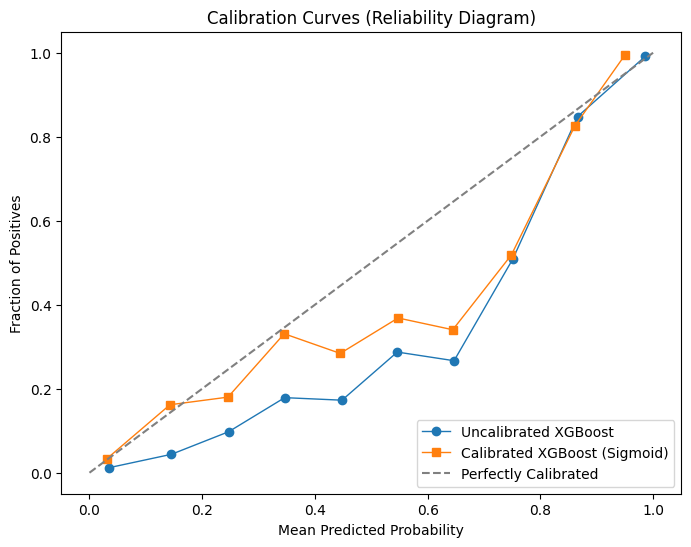

In [ ]:
# 4. plot

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(predict_uncal, acutal_uncal, marker='o', linewidth=1, label='Uncalibrated XGBoost')
plt.plot(predict_cal, acutal_cal, marker='s', linewidth=1, label='Calibrated XGBoost (Sigmoid)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curves (Reliability Diagram)')
plt.legend(loc='lower right')

plt.show()

In [ ]:
!pip install shap
import shap

In [ ]:
# 1. Get the Trained XGBoost classifier model out of the pipeline
xgb_classifier = xg_model.named_steps['classifier']


In [ ]:
# 2. Transform X_test using the same preprocessing used for traininng.
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [ ]:
# 3. Get feature names after one- hot encoding , so plots are readable

feature_names =xg_model.named_steps['preprocessor'].get_feature_names_out()

In [ ]:
# 4. Convert to a dataframe for cleaner SHAP plots

X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [ ]:
# 6. Create SHAP explainer build for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [ ]:
explainer

In [ ]:
# 7. Calc SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-1.6896079e-01,  4.4341248e-02,  2.9599199e-01, ...,
        -8.4896227e-03, -3.7767626e-02,  0.0000000e+00],
       [ 7.5152241e-02, -1.1325309e+00,  9.0570986e-02, ...,
        -9.2896437e-03,  1.3286404e-02,  0.0000000e+00],
       [ 1.1188781e-01,  4.1302185e+00,  5.3409860e-02, ...,
        -7.5205197e-03,  1.2012657e-02,  0.0000000e+00],
       ...,
       [ 1.2044956e-02,  8.4634709e-01,  1.4048249e-01, ...,
        -9.5348777e-03, -2.0864941e-03,  0.0000000e+00],
       [ 2.0871323e-02, -1.1192774e+00, -6.6748741e-03, ...,
        -1.0299177e-02, -1.7510228e-02,  0.0000000e+00],
       [-2.7903911e-01, -1.2437960e+00,  4.1031312e-02, ...,
        -9.7654387e-03,  8.4219836e-03,  0.0000000e+00]],
      shape=(6305, 26), dtype=float32)

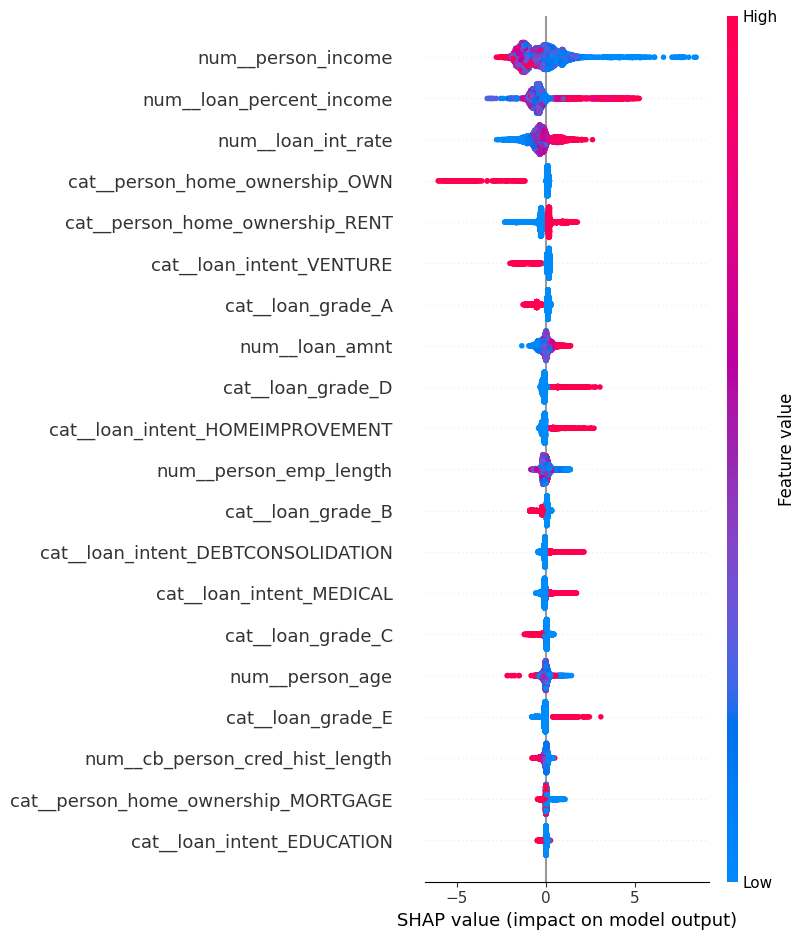

In [ ]:
shap.summary_plot(shap_values, X_test_df,)

In [ ]:
shap_values[5]

array([ 9.02931914e-02, -1.15875936e+00, -6.73301071e-02, -7.26718754e-02,
       -5.01148582e-01, -3.41039509e-01,  2.96892375e-02,  9.09246318e-03,
       -4.05935250e-04,  9.31593403e-02, -3.21743965e-01, -4.66145612e-02,
        1.03117591e-02, -5.43668196e-02, -8.47082809e-02, -1.28533784e-02,
        1.85481578e-01,  1.18952662e-01, -2.22124681e-01,  4.52090353e-02,
       -1.24621704e-01, -3.10443733e-02, -1.96049213e-02, -9.96783376e-03,
       -2.14705779e-03,  0.00000000e+00], dtype=float32)

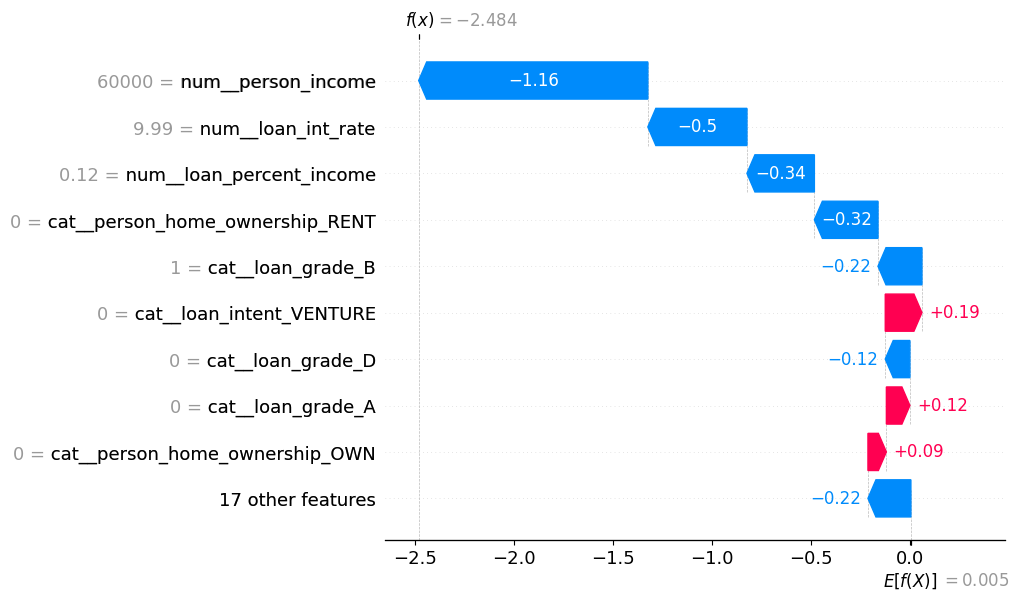

In [ ]:
#1. Pick one row to explain,
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down

shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,# what model can predict for the particular
        data = X_test_df.iloc[row_index],
        feature_names = X_test_df.columns
    )
)

In [ ]:
#Get predictions from the best performing XGBoost model on the test set
y_pred = random_search.predict(X_test)

In [ ]:

#Create a dataframe to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [ ]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [ ]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 217
False Negative : 268


In [ ]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [ ]:
import numpy as np
import joblib
from sklearn.metrics import precision_recall_curve

# Calculate the best threshold from the random search model predictions
y_pred_proba = random_search.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)
f1 = 2 * (precisions - recalls) / (precisions + recalls + 1e-8)
best = np.argmax(f1[:-1])
best_thres = thresholds[best]

# Save the threshold
joblib.dump(best_thres, "best_threshold.pkl")

['best_threshold.pkl']

In [ ]:
import numpy as np
import joblib
from sklearn.metrics import precision_recall_curve

# Calculate the best threshold from the random search model predictions
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test,calibrated_proba)
f1 = 2 * (precisions - recalls) / (precisions + recalls + 1e-9)
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

# Save the threshold
joblib.dump(best_thres, "New_Best_threshold.pkl")
print("New Threshold",best_threshold)

New Threshold 0.9558412808808299
